
# Phase 6.1 - Clustering de Contexto Mejorado (desde Phase 5.3/3.5)

Objetivo: mejorar "palabras/regímenes" usando como base el mejor modelo de la línea 3.5 (`v5.1_kwalk`) y una configuración de contexto más robusta.

Mejoras clave respecto a v6:
- Fuente: `phase5 v5.1` (3.5), no `v5.2`.
- Contexto de secuencia: `CONTEXT_LEN=24` con n-gramas `(1,2)`.
- Selección de `K` con score robusto: `eta_wf + cobertura + balance + clusters activos`.


base rows = 1605
base split = {'train': 1123, 'val': 241, 'test': 241}
context rows = 1582
context split = {'train': 1100, 'val': 241, 'test': 241}
folds = [(670, 134), (804, 134), (938, 134), (1072, 134)]


BEST_K = 11


,k,eta_wf,cov_wf,bal_wf,act_wf,z_eta,z_cov,z_bal,z_act,wf_score
0,11,0.022747,0.908582,0.368235,3.75,2.062750,-0.582688,-0.006968,0.914891,3.045571
1,10,0.017731,0.906716,0.315842,3.75,1.198345,-0.651690,-0.872904,0.914891,0.994265
2,12,0.011639,0.908582,0.425278,3.75,0.148485,-0.582688,0.935812,0.914891,0.642692
3,5,0.009826,0.930970,0.466768,2.00,-0.163874,0.245342,1.621552,-1.591115,0.616362
4,6,0.011097,0.962687,0.283044,3.25,0.055049,1.418385,-1.414968,0.198889,0.433814
5,4,0.005175,0.979478,0.326920,2.00,-0.965348,2.039407,-0.689798,-1.591115,-0.669284
6,8,0.008634,0.904851,0.328713,3.50,-0.369282,-0.720693,-0.660163,0.556890,-1.534521
7,7,0.002997,0.921642,0.448960,2.50,-1.340836,-0.099670,1.327232,-0.875113,-1.568513
8,9,0.007149,0.895522,0.354148,3.50,-0.625289,-1.065705,-0.239793,0.556890,-1.960386


saved summary = ./phases/phase06_context_regimes/output_context_words_GBPUSD_v6_1_from_v5_1/GBPUSD_context_words_summary_v6_1.json
test words v6.1 -> kw_p: 0.032893936181452775 | anova_p: 0.09889146183013417 | eta2: 0.03582682383582168


,word_id,n,mean_ret,median_ret,std_ret,t_like
0,5,94,0.712770,1.999736,140.373054,0.005078
1,10,37,-32.170141,-34.399033,87.920215,-0.365902
2,6,34,28.661700,34.599900,101.350640,0.282797
3,1,27,-45.581570,-51.599741,103.230455,-0.441552
4,0,26,-12.553930,7.149577,112.666451,-0.111426
5,2,19,12.563279,-2.000332,73.990545,0.169796
6,9,4,-24.350584,-18.150806,124.347348,-0.195827


,word_id,word_token,ctx_window_id,start_ts,end_ts,word_dist,token_text
0,0,w00,1111,2016-07-29 04:00:00,2017-02-10 00:00:00,3.399497,r01 r01 r01 r03 r03 r03 r03 r03 r01 r01 r05 r0...
1,0,w00,1113,2016-08-05 02:00:00,2017-02-16 22:00:00,3.399497,r01 r03 r03 r03 r03 r03 r01 r01 r05 r05 r05 r0...
2,0,w00,1112,2016-08-04 01:00:00,2017-02-13 22:00:00,3.399497,r01 r01 r03 r03 r03 r03 r03 r01 r01 r05 r05 r0...
3,0,w00,739,2010-04-27 05:00:00,2010-09-30 03:00:00,3.580935,r01 r01 r01 r01 r01 r01 r01 r01 r01 r01 r01 r0...
4,0,w00,740,2010-04-27 22:00:00,2010-10-07 01:00:00,3.649816,r01 r01 r01 r01 r01 r01 r01 r01 r01 r01 r01 r0...
5,1,w01,1311,2019-10-01 22:00:00,2020-05-27 04:00:00,2.979814,r00 r00 r00 r00 r00 r00 r00 r00 r00 r00 r00 r0...
6,1,w01,1310,2019-10-01 06:00:00,2020-05-18 20:00:00,2.991331,r00 r00 r00 r00 r00 r00 r00 r00 r00 r00 r00 r0...
7,1,w01,1312,2019-10-03 02:00:00,2020-06-01 04:00:00,3.011548,r00 r00 r00 r00 r00 r00 r00 r00 r00 r00 r05 r0...
8,1,w01,1309,2019-09-26 21:00:00,2020-05-13 04:00:00,3.045379,r00 r00 r00 r00 r00 r00 r00 r00 r00 r00 r00 r0...
9,1,w01,820,2011-01-09 21:00:00,2011-10-19 23:00:00,3.058452,r00 r00 r00 r00 r00 r00 r00 r00 r00 r00 r00 r0...


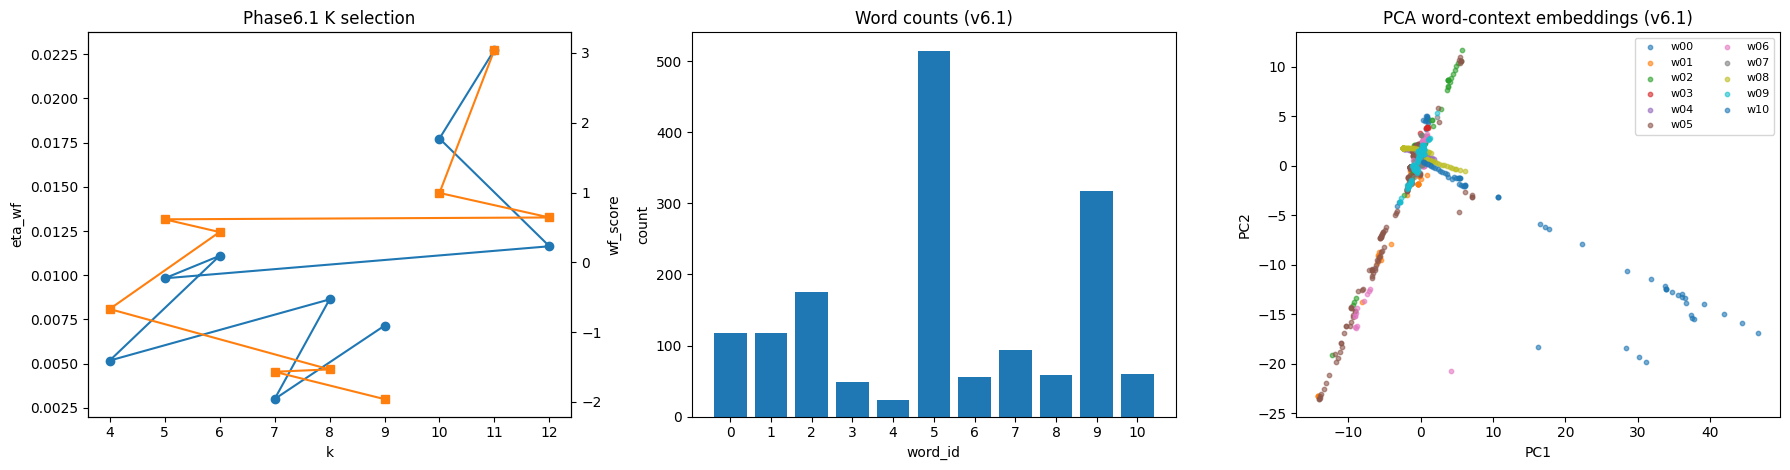

In [1]:

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.stats import kruskal, f_oneway

pd.set_option('display.max_columns', 260)
pd.set_option('display.width', 340)

# =========================
# Config
# =========================
SEED = 42
SYMBOL = 'GBPUSD'
CONTEXT_LEN = 24
NGRAM_RANGE = (1, 2)
MIN_DF = 2
MAX_DF = 0.95
SVD_DIM = 32

K_CANDIDATES = list(range(4, 13))
N_INIT_KMEANS = 50
MIN_CLUSTER_N_FOLD = 15
MIN_CLUSTER_N_TEST = 20

FOLD_SPECS = [
    (0.50, 0.10),
    (0.60, 0.10),
    (0.70, 0.10),
    (0.80, 0.10),
]

ROOT = Path('.')
IN_PQ = ROOT / 'phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v5_kwalk/GBPUSD_context_window_embeddings_v5_1.parquet'
IN_SUM_V51 = ROOT / 'phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v5_kwalk/GBPUSD_superclustering_summary_v5_1.json'
IN_SUM_V6 = ROOT / 'phases/phase06_context_regimes/output_context_words_GBPUSD_v6/GBPUSD_context_words_summary_v6.json'

OUT_DIR = ROOT / 'phases/phase06_context_regimes/output_context_words_GBPUSD_v6_1_from_v5_1'
OUT_DIR.mkdir(parents=True, exist_ok=True)

WORDS_PQ = OUT_DIR / 'GBPUSD_context_words_windows_v6_1.parquet'
WORDS_CSV = OUT_DIR / 'GBPUSD_context_words_windows_v6_1.csv'
PROFILE_CSV = OUT_DIR / 'GBPUSD_context_words_profile_v6_1.csv'
TRANS_CSV = OUT_DIR / 'GBPUSD_context_words_transition_matrix_v6_1.csv'
MODEL_SEL_CSV = OUT_DIR / 'GBPUSD_context_words_k_selection_v6_1.csv'
PROTOTYPES_CSV = OUT_DIR / 'GBPUSD_context_words_prototypes_v6_1.csv'
SUMMARY_JSON = OUT_DIR / 'GBPUSD_context_words_summary_v6_1.json'

np.random.seed(SEED)


def zscore_col(x: pd.Series):
    s = pd.to_numeric(x, errors='coerce')
    m = float(s.mean())
    sd = float(s.std(ddof=0))
    if not np.isfinite(sd) or sd < 1e-9:
        return pd.Series(np.zeros(len(s)), index=s.index, dtype=float)
    return (s - m) / (sd + 1e-9)


def build_folds(idx_tv: np.ndarray):
    n = len(idx_tv)
    folds = []
    for tr, va in FOLD_SPECS:
        a = int(n * tr)
        b = min(n, int(n * (tr + va)))
        if b - a >= 30:
            folds.append((idx_tv[:a], idx_tv[a:b]))
    return folds


# =========================
# Load base stream from v5.1
# =========================
base = pd.read_parquet(IN_PQ).copy()
base['start_ts'] = pd.to_datetime(base['start_ts'], errors='coerce')
base['end_ts'] = pd.to_datetime(base['end_ts'], errors='coerce')
base = base.sort_values(['end_ts', 'window_id']).reset_index(drop=True)

required = ['window_id', 'start_ts', 'end_ts', 'split', 'regime_id', 'regime_token', 'ret_fwd_24h_pips']
miss = [c for c in required if c not in base.columns]
if miss:
    raise ValueError(f'Missing columns: {miss}')

print('base rows =', len(base))
print('base split =', base['split'].value_counts().to_dict())

# =========================
# Build context windows
# =========================
reg_tokens = base['regime_token'].astype(str).to_numpy()
reg_ids = base['regime_id'].astype(int).to_numpy()
splits = base['split'].astype(str).to_numpy()
rets = pd.to_numeric(base['ret_fwd_24h_pips'], errors='coerce').to_numpy(dtype=float)
starts = base['start_ts'].to_numpy(dtype='datetime64[ns]')
ends = base['end_ts'].to_numpy(dtype='datetime64[ns]')
window_ids = base['window_id'].to_numpy(dtype=int)

rows = []
for i in range(CONTEXT_LEN - 1, len(base)):
    j0 = i - CONTEXT_LEN + 1
    seq = reg_tokens[j0:i+1]
    rows.append({
        'ctx_window_id': int(i - (CONTEXT_LEN - 1)),
        'base_window_id_end': int(window_ids[i]),
        'start_ts': pd.Timestamp(starts[j0]),
        'end_ts': pd.Timestamp(ends[i]),
        'split': str(splits[i]),
        'token_seq': seq.tolist(),
        'token_text': ' '.join(seq.tolist()),
        'last_regime_id': int(reg_ids[i]),
        'ret_fwd_24h_pips': float(rets[i]) if np.isfinite(rets[i]) else np.nan,
    })

CTX = pd.DataFrame(rows)
print('context rows =', len(CTX))
print('context split =', CTX['split'].value_counts().to_dict())

idx_tr = np.where(CTX['split'].to_numpy() == 'train')[0]
idx_va = np.where(CTX['split'].to_numpy() == 'val')[0]
idx_te = np.where(CTX['split'].to_numpy() == 'test')[0]
idx_tv = np.concatenate([idx_tr, idx_va])

texts = CTX['token_text'].astype(str).to_numpy()
ret_ctx = pd.to_numeric(CTX['ret_fwd_24h_pips'], errors='coerce').to_numpy(dtype=float)

# =========================
# K selection (walk-forward robust)
# =========================
folds = build_folds(idx_tv)
print('folds =', [(len(a), len(b)) for a, b in folds])

rows_sel = []
for k in K_CANDIDATES:
    eta_f, cov_f, bal_f, act_f = [], [], [], []

    for tr_i, va_i in folds:
        vec = TfidfVectorizer(
            analyzer='word',
            lowercase=False,
            token_pattern=r'[^\s]+',
            ngram_range=NGRAM_RANGE,
            min_df=MIN_DF,
            max_df=MAX_DF,
        )
        Xtr = vec.fit_transform(texts[tr_i])
        Xva = vec.transform(texts[va_i])

        if Xtr.shape[1] <= 2:
            Ztr = Xtr.toarray()
            Zva = Xva.toarray()
        else:
            n_comp = int(min(SVD_DIM, max(2, Xtr.shape[1] - 1)))
            svd = TruncatedSVD(n_components=n_comp, random_state=SEED)
            Ztr = svd.fit_transform(Xtr)
            Zva = svd.transform(Xva)

        sc = StandardScaler()
        Ztr = sc.fit_transform(Ztr)
        Zva = sc.transform(Zva)

        lv = KMeans(n_clusters=k, n_init=N_INIT_KMEANS, random_state=SEED).fit(Ztr).predict(Zva)

        cnt = pd.Series(lv).value_counts()
        active = cnt[cnt >= MIN_CLUSTER_N_FOLD]
        cov_f.append(float(active.sum() / len(lv)))
        bal_f.append(float(active.min() / active.max()) if len(active) else 0.0)
        act_f.append(float(len(active)))

        rv = ret_ctx[va_i]
        m = np.isfinite(rv)
        l = lv[m]
        r = rv[m]

        groups = []
        for cid in np.unique(l):
            g = r[l == cid]
            if len(g) >= MIN_CLUSTER_N_FOLD:
                groups.append(g)

        if len(groups) >= 2:
            allv = np.concatenate(groups)
            gm = np.mean(allv)
            ssb = sum(len(g) * (np.mean(g) - gm) ** 2 for g in groups)
            sst = np.sum((allv - gm) ** 2)
            eta_f.append(float(ssb / sst) if sst > 0 else np.nan)

    rows_sel.append({
        'k': int(k),
        'eta_wf': float(np.nanmean(eta_f)) if eta_f else np.nan,
        'cov_wf': float(np.nanmean(cov_f)) if cov_f else np.nan,
        'bal_wf': float(np.nanmean(bal_f)) if bal_f else np.nan,
        'act_wf': float(np.nanmean(act_f)) if act_f else np.nan,
    })

SEL = pd.DataFrame(rows_sel)
SEL['z_eta'] = zscore_col(SEL['eta_wf'])
SEL['z_cov'] = zscore_col(SEL['cov_wf'])
SEL['z_bal'] = zscore_col(SEL['bal_wf'])
SEL['z_act'] = zscore_col(SEL['act_wf'])

# tuned robust score (more weight on separation + coverage/balance)
SEL['wf_score'] = 1.6*SEL['z_eta'] + 0.9*SEL['z_cov'] + 0.7*SEL['z_bal'] + 0.3*SEL['z_act']
SEL = SEL.sort_values('wf_score', ascending=False).reset_index(drop=True)
SEL.to_csv(MODEL_SEL_CSV, index=False)

BEST_K = int(SEL.iloc[0]['k'])
print('BEST_K =', BEST_K)
display(SEL)

# =========================
# Final fit train+val -> all
# =========================
vec_final = TfidfVectorizer(
    analyzer='word',
    lowercase=False,
    token_pattern=r'[^\s]+',
    ngram_range=NGRAM_RANGE,
    min_df=MIN_DF,
    max_df=MAX_DF,
)
Xtv = vec_final.fit_transform(texts[idx_tv])
Xall = vec_final.transform(texts)

if Xtv.shape[1] <= 2:
    Ztv = Xtv.toarray()
    Zall = Xall.toarray()
else:
    n_comp = int(min(SVD_DIM, max(2, Xtv.shape[1] - 1)))
    svd_final = TruncatedSVD(n_components=n_comp, random_state=SEED)
    Ztv = svd_final.fit_transform(Xtv)
    Zall = svd_final.transform(Xall)

sc_final = StandardScaler()
Ztv = sc_final.fit_transform(Ztv)
Zall = sc_final.transform(Zall)

KM = KMeans(n_clusters=BEST_K, n_init=N_INIT_KMEANS, random_state=SEED)
KM.fit(Ztv)
word_id = KM.predict(Zall)
word_dist = KM.transform(Zall).min(axis=1)

OUT = CTX[['ctx_window_id', 'base_window_id_end', 'start_ts', 'end_ts', 'split', 'token_seq', 'token_text', 'last_regime_id', 'ret_fwd_24h_pips']].copy()
OUT['word_id'] = word_id.astype(int)
OUT['word_token'] = OUT['word_id'].map(lambda x: f'w{x:02d}')
OUT['word_dist'] = word_dist.astype(float)

for j in range(min(Zall.shape[1], 64)):
    OUT[f'word_emb_{j:03d}'] = Zall[:, j]

# =========================
# Test profile + significance
# =========================
test_df = OUT[OUT['split'] == 'test'].copy()
prof = (test_df.groupby('word_id')['ret_fwd_24h_pips']
        .agg(n='count', mean_ret='mean', median_ret='median', std_ret='std')
        .reset_index())
prof['t_like'] = prof['mean_ret'] / prof['std_ret'].replace(0, np.nan)
prof = prof.sort_values('n', ascending=False).reset_index(drop=True)

kw_p = np.nan
anova_p = np.nan
eta2 = np.nan

groups = []
for _, g in test_df.groupby('word_id'):
    x = pd.to_numeric(g['ret_fwd_24h_pips'], errors='coerce').dropna().to_numpy()
    if len(x) >= MIN_CLUSTER_N_TEST:
        groups.append(x)

if len(groups) >= 2:
    kw_p = float(kruskal(*groups).pvalue)
    anova_p = float(f_oneway(*groups).pvalue)
    allv = np.concatenate(groups)
    gm = np.mean(allv)
    ssb = sum(len(g) * (np.mean(g) - gm) ** 2 for g in groups)
    sst = np.sum((allv - gm) ** 2)
    eta2 = float(ssb / sst) if sst > 0 else np.nan

tr = pd.crosstab(OUT['word_token'], OUT['word_token'].shift(-1)).fillna(0)
tr_prob = tr.div(tr.sum(axis=1), axis=0).fillna(0.0)

# prototypes
proto_rows = []
for w in sorted(OUT['word_id'].unique()):
    d = OUT[OUT['word_id'] == w].copy().sort_values('word_dist').head(5)
    for _, r in d.iterrows():
        proto_rows.append({
            'word_id': int(w),
            'word_token': f'w{int(w):02d}',
            'ctx_window_id': int(r['ctx_window_id']),
            'start_ts': pd.Timestamp(r['start_ts']),
            'end_ts': pd.Timestamp(r['end_ts']),
            'word_dist': float(r['word_dist']),
            'token_text': str(r['token_text']),
        })
PROT = pd.DataFrame(proto_rows)

# save
OUT.to_parquet(WORDS_PQ, index=False)
OUT.to_csv(WORDS_CSV, index=False)
prof.to_csv(PROFILE_CSV, index=False)
tr_prob.to_csv(TRANS_CSV)
PROT.to_csv(PROTOTYPES_CSV, index=False)

sum_v51 = json.loads(IN_SUM_V51.read_text()) if IN_SUM_V51.exists() else {}
sum_v6 = json.loads(IN_SUM_V6.read_text()) if IN_SUM_V6.exists() else {}

summary = {
    'symbol': SYMBOL,
    'model_tag': 'phase6_context_words_v6_1_from_v5_1',
    'source_model': 'phase5_v5_1_kwalk',
    'n_base_windows': int(len(base)),
    'n_context_windows': int(len(OUT)),
    'context_len': int(CONTEXT_LEN),
    'ngram_range': list(NGRAM_RANGE),
    'min_df': int(MIN_DF),
    'svd_dim': int(SVD_DIM),
    'best_k_words': int(BEST_K),
    'split_counts': {k: int(v) for k, v in OUT['split'].value_counts().to_dict().items()},
    'kw_pvalue_test': None if not np.isfinite(kw_p) else float(kw_p),
    'anova_pvalue_test': None if not np.isfinite(anova_p) else float(anova_p),
    'eta2_test': None if not np.isfinite(eta2) else float(eta2),
    'wf_score_best_k': float(SEL.iloc[0]['wf_score']),
    'wf_eta_best_k': None if not np.isfinite(SEL.iloc[0]['eta_wf']) else float(SEL.iloc[0]['eta_wf']),
    'wf_cov_best_k': None if not np.isfinite(SEL.iloc[0]['cov_wf']) else float(SEL.iloc[0]['cov_wf']),
    'wf_bal_best_k': None if not np.isfinite(SEL.iloc[0]['bal_wf']) else float(SEL.iloc[0]['bal_wf']),
    'baseline_phase5_v5_1_eta2_test': sum_v51.get('eta2_test'),
    'baseline_phase5_v5_1_kw_pvalue_test': sum_v51.get('kw_pvalue_test'),
    'previous_phase6_v6_eta2_test': sum_v6.get('eta2_test'),
    'previous_phase6_v6_kw_pvalue_test': sum_v6.get('kw_pvalue_test'),
}
SUMMARY_JSON.write_text(json.dumps(summary, indent=2))

print('saved summary =', SUMMARY_JSON)
print('test words v6.1 -> kw_p:', kw_p, '| anova_p:', anova_p, '| eta2:', eta2)
display(prof)
display(PROT.head(15))

# =========================
# Diagnostics
# =========================
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

axes[0].plot(SEL['k'], SEL['eta_wf'], marker='o', label='eta_wf')
ax2 = axes[0].twinx()
ax2.plot(SEL['k'], SEL['wf_score'], marker='s', color='tab:orange', label='wf_score')
axes[0].set_title('Phase6.1 K selection')
axes[0].set_xlabel('k')
axes[0].set_ylabel('eta_wf')
ax2.set_ylabel('wf_score')

cnt = OUT['word_id'].value_counts().sort_index()
axes[1].bar(cnt.index.astype(str), cnt.values)
axes[1].set_title('Word counts (v6.1)')
axes[1].set_xlabel('word_id')
axes[1].set_ylabel('count')

emb_cols = [c for c in OUT.columns if c.startswith('word_emb_')]
E = OUT[emb_cols].to_numpy(dtype=float)
if E.shape[1] >= 2:
    xy = PCA(n_components=2, random_state=SEED).fit_transform(E)
    for w in sorted(OUT['word_id'].unique()):
        m = OUT['word_id'].to_numpy() == w
        axes[2].scatter(xy[m, 0], xy[m, 1], s=10, alpha=0.6, label=f'w{w:02d}')
    axes[2].legend(ncol=2, fontsize=8)
axes[2].set_title('PCA word-context embeddings (v6.1)')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')

plt.tight_layout()
plt.show()
